[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/Synergetics/blob/main/syn_py_ua/syn_ua_10_stochastic_synergetics.ipynb)


# 10. Шум, динаміка Фоккера—Планка і перемикання

_Магістерський курс «Вступ до синергетики» · українська версія_

> **Провідне питання:** Коли шум виявляє, зміщує або навіть породжує макроскопічну поведінку поблизу переходу?

**Як працювати з ноутбуком.** Виконуйте комірки послідовно, згори донизу. Якщо не зазначено інше, усі параметри безрозмірні. Пояснюйте зміст кожної діагностики: сама лише ефектна траєкторія ще не доводить самоорганізації.


## Результати навчання

Після опрацювання модуля ви зможете:

- означити марковський процес, вінерівський приріст і стохастичне диференціальне рівняння Іто;
- пояснити поправку у формулі Іто через квадратичну варіацію;
- переходити між рівнянням Ланжевена у границі сильного тертя і відповідним рівнянням Фоккера—Планка;
- перевіряти схему Ейлера—Маруями за точними моментами процесу Орнштейна—Уленбека;
- виводити стаціонарну густину для градієнтного дрейфу;
- оцінювати статистику перемикань і розпізнавати похибку дискретизації.


## Мова ймовірностей: траєкторія, ансамбль і марковський стан

Випадкова величина $X$ ставить у відповідність числове значення кожному результату випробування. **Стохастичний процес** $X_t$ — це сімейство випадкових величин, індексоване часом. Одна реалізація $t\mapsto X_t$ є вибірковою траєкторією; повторення випробування дає ансамбль траєкторій. Густина ймовірності $p(x,t)$ відповідає на ансамблеве питання, тоді як часовий ряд є лише однією траєкторією. Замінювати ансамблеве середнє довгочасовим можна тільки за додаткового обґрунтування ергодичності.

Процес є **марковським**, якщо після задання теперішнього стану умовний розподіл майбутнього не потребує попередньої історії:

$$p(x_3,t_3\mid x_2,t_2;x_1,t_1)=p(x_3,t_3\mid x_2,t_2),\qquad t_1<t_2<t_3.$$

Густини переходу композиційно пов'язані рівнянням Чепмена—Колмогорова,

$$p(x_3,t_3\mid x_1,t_1)=\int p(x_3,t_3\mid x_2,t_2)p(x_2,t_2\mid x_1,t_1)\,dx_2.$$

Цей закон композиції є ймовірнісним вихідним пунктом для кінетичних рівнянь. Короткочасовий розклад за умовними моментами стрибків дає ряд Крамерса—Мояла; збереження членів дрейфу та дифузії приводить до рівняння Фоккера—Планка.


## Вінерівський рух і зміст рівняння Іто

Стандартний вінерівський процес $W_t$ має $W_0=0$, незалежні гауссові прирости та

$$\Delta W=W_{t+\Delta t}-W_t\sim\mathcal N(0,\Delta t).$$

Отже, типовий масштаб $\Delta W$ дорівнює $\sqrt{\Delta t}$, а не $\Delta t$. Траєкторії неперервні, але ніде не диференційовані у класичному сенсі; «білий шум» $\xi(t)=dW_t/dt$ є лише формальним записом. Стохастичне диференціальне рівняння Іто

$$dX_t=a(X_t,t)\,dt+b(X_t,t)\,dW_t$$

означає інтегральне рівняння, де випадковий підінтегральний множник береться на початку кожного часового інтервалу. Тут $a$ — дрейф, а $b^2$ — локальна швидкість наростання дисперсії. Для моделювання використаємо схему Ейлера—Маруями:

$$X_{n+1}=X_n+a(X_n,t_n)\Delta t+b(X_n,t_n)\sqrt{\Delta t}\,Z_n,
\qquad Z_n\sim\mathcal N(0,1).$$

Поширена помилка — множити гауссову випадкову величину на $\Delta t$. У неперервній границі накопичений таким чином шум зникає.


## Чому звичайні правила аналізу змінюються: квадратична варіація і формула Іто

Оскільки $(\Delta W)^2$ має порядок $\Delta t$, член другого порядку в розкладі Тейлора не зникає. У символічних правилах Іто

$$(dW)^2=dt,\qquad dW\,dt=0,\qquad (dt)^2=0.$$

Якщо $dX=a\,dt+b\,dW$ та $F=F(X,t)$, то

$$dF=\left(\partial_tF+a\,\partial_xF+\frac12b^2\partial_x^2F\right)dt
+b\,\partial_xF\,dW.$$

У найпростішому прикладі $X=W$ і $F=X^2$, тому $d(W^2)=2W\,dW+dt$. Додатковий член $dt$ не можна відкинути: саме він забезпечує $\mathbb E[W_t^2]=t$.

За шуму, залежного від стану, важливо вказати інтерпретацію. Рівняння Стратоновича $dX=a_Sdt+b\circ dW$ еквівалентне рівнянню Іто з $a_I=a_S+\tfrac12b\,\partial_xb$. Для адитивного шуму, коли $b$ стала, обидві інтерпретації збігаються. Модель із мультиплікативним шумом має обов'язково зазначати конвенцію та фізичну граничну процедуру.


## Від вибіркових траєкторій до еволюції густини

Застосування формули Іто до довільної гладкої пробної функції та інтегрування частинами дає пряме рівняння Фоккера—Планка

$$\partial_tp(x,t)=-\partial_x[a(x,t)p(x,t)]
+\frac12\partial_x^2[b^2(x,t)p(x,t)].$$

Це закон збереження $\partial_tp=-\partial_xJ$ зі струмом імовірності

$$J=a p-\frac12\partial_x(b^2p).$$

Початкові й граничні умови є частиною моделі: відбивальні межі задають $J=0$, а поглинальні — $p=0$. Нормування, невід'ємність і збіг моментів густини з ансамблем траєкторій є обов'язковими числовими перевірками. Стохастичне рівняння та рівняння Фоккера—Планка — два описи однієї марковської дифузії: перше розвиває випадкові траєкторії, друге — їхню густину ймовірності.


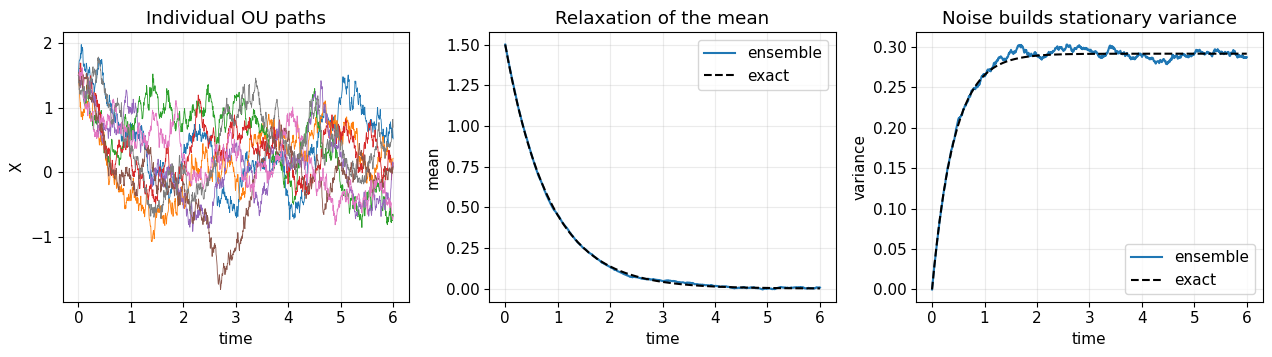

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (7.2, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})
rng = np.random.default_rng(20260904)

# Ornstein-Uhlenbeck process: the basic relaxation-plus-noise benchmark.
gamma_ou, D_ou, dt_ou, t_end_ou = 1.2, 0.35, 0.005, 6.0
steps_ou = int(t_end_ou/dt_ou)
paths_ou, x0_ou = 5000, 1.5
x_ou = np.full(paths_ou, x0_ou)
mean_ou = np.empty(steps_ou + 1)
var_ou = np.empty(steps_ou + 1)
mean_ou[0], var_ou[0] = x_ou.mean(), x_ou.var()
sample_ou = np.empty((8, steps_ou + 1))
sample_ou[:, 0] = x_ou[:8]

for n in range(steps_ou):
    x_ou += -gamma_ou*x_ou*dt_ou + np.sqrt(2*D_ou*dt_ou)*rng.standard_normal(paths_ou)
    mean_ou[n+1], var_ou[n+1] = x_ou.mean(), x_ou.var()
    sample_ou[:, n+1] = x_ou[:8]

t_ou = np.arange(steps_ou + 1)*dt_ou
mean_exact = x0_ou*np.exp(-gamma_ou*t_ou)
var_exact = D_ou/gamma_ou*(1-np.exp(-2*gamma_ou*t_ou))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.7))
ax[0].plot(t_ou, sample_ou.T, lw=0.6)
ax[0].set(xlabel="time", ylabel="X", title="Individual OU paths")
ax[1].plot(t_ou, mean_ou, label="ensemble")
ax[1].plot(t_ou, mean_exact, "k--", label="exact")
ax[1].set(xlabel="time", ylabel="mean", title="Relaxation of the mean")
ax[1].legend()
ax[2].plot(t_ou, var_ou, label="ensemble")
ax[2].plot(t_ou, var_exact, "k--", label="exact")
ax[2].set(xlabel="time", ylabel="variance", title="Noise builds stationary variance")
ax[2].legend()
plt.tight_layout()


## Шумова динаміка параметра порядку

Для процесу Іто

$$dx=-V'(x)dt+\sqrt{2D}\,dW_t$$

густина еволюціонує за рівнянням

$$\partial_tp=\partial_x[V'(x)p]+D\partial_x^2p.$$

За нульового струму ймовірності $p_s(x)\propto e^{-V(x)/D}$. Для $V=x^4/4-ax^2/2-hx$ дві ями відповідають конкуруючим макростанам. Слабкий шум спричиняє рідкісні переходи через бар'єр; зі зростанням $D$ локальні флуктуації розширюються, а перемикання пришвидшуються.


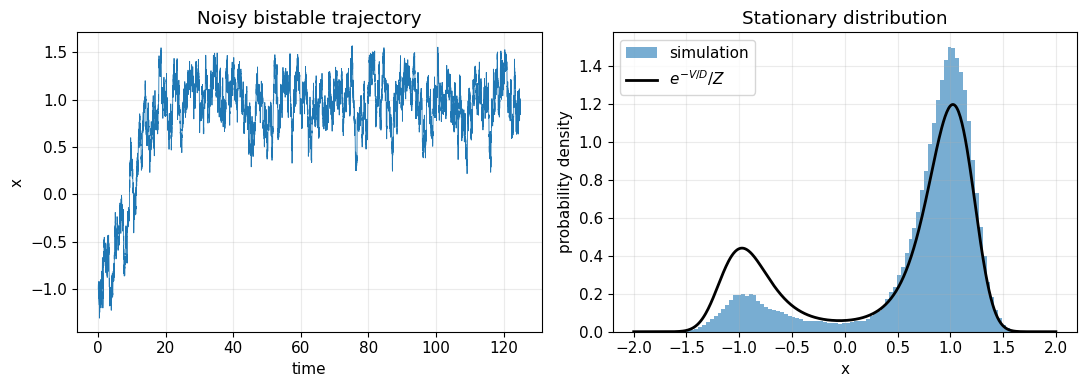

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (7.2, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})
rng = np.random.default_rng(20260904)

a, h, D = 1.0, 0.05, 0.10
dt, steps = 0.005, 400000
x = np.empty(steps)
x[0] = -1.0
for n in range(steps-1):
    drift = a*x[n] - x[n]**3 + h
    x[n+1] = x[n] + drift*dt + np.sqrt(2*D*dt)*rng.standard_normal()

grid = np.linspace(-2.0, 2.0, 500)
V = grid**4/4 - a*grid**2/2 - h*grid
p = np.exp(-(V-V.min())/D)
p /= np.trapezoid(p, grid)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(np.arange(25000)*dt, x[:25000], lw=0.6)
ax[0].set(xlabel="time", ylabel="x", title="Noisy bistable trajectory")
ax[1].hist(x[50000:], bins=90, density=True, alpha=0.6, label="simulation")
ax[1].plot(grid, p, "k", lw=2, label=r"$e^{-V/D}/Z$")
ax[1].set(xlabel="x", ylabel="probability density", title="Stationary distribution")
ax[1].legend()
plt.tight_layout()


## Що саме вимірювати

Гістограма перевіряє стаціонарну міру, але втрачає часову інформацію. Для аналізу перемикань потрібні операційне означення стану з двома гістерезисними порогами, розподіли часів перебування та оцінки невизначеності. Схема Ейлера—Маруями має скінченно-крокове зміщення; перш ніж називати розбіжність фізичним ефектом, повторіть розрахунок із меншим $dt$.


## Оцінюване завдання

Частина A: повторіть моделювання процесу Орнштейна—Уленбека для трьох кроків часу. Порівняйте емпіричні середнє та дисперсію з точними формулами й визначте тенденцію слабкої збіжності. Частина B: для щонайменше чотирьох інтенсивностей шуму в бістабільній моделі оцініть середні часи перебування, використовуючи двопорогове розпізнавання станів. Перевірте очікування Арреніуса—Крамерса графіком $\log\tau$ від $1/D$ і визначте, де асимптотичне співвідношення перестає працювати.

Подання має містити чітке твердження, його математичне або фізичне обґрунтування, числові свідчення та принаймні одне обмеження висновку.


## Література та атрибуція

**Основне читання з локальної бібліотеки:** українські конспекти з нерівноважної статистичної фізики та фізичної кінетики — розділи про марковські процеси, рівняння Чепмена—Колмогорова, динаміку Ланжевена, рівняння Фоккера—Планка та числення Іто—Стратоновича; Haken, *Synergetics: An Introduction*, розділи про флуктуації й нерівноважні переходи.

**Перевірені англомовні вебджерела:**
- [Gardiner, Stochastic Methods](https://link.springer.com/book/9783540707127)
- [Risken, The Fokker–Planck Equation](https://doi.org/10.1007/978-3-642-61544-3)
- [van Kampen, Stochastic Processes in Physics and Chemistry](https://shop.elsevier.com/books/stochastic-processes-in-physics-and-chemistry/van-kampen/978-0-444-52965-7)
- [Haken, Synergetics: An Introduction](https://doi.org/10.1007/978-3-642-88338-5)

Локальні книги є наданими матеріалами курсу. Вебпосилання мають додатковий характер; їх перевірено 04.09.2026.
